# AML Baseline 1 — ConvNeXt-Tiny (ImageNet-1K V1)

This notebook implements **Baseline 1** for compositional crop–disease classification using two independent ConvNeXt-Tiny CNNs: Crop (55 classes) and Disease (175 classes). Both models are initialised with ImageNet-1K V1 pretrained weights and trained using full fine-tuning.

The experiment adopts the selected **ResNet-50 Higher Weight Decay hyperparameters** to evaluate their effectiveness with ConvNeXt-Tiny.

### Model Configuration

| Hyperparameter | Value |
|---|---|
| Backbone | ConvNeXt-Tiny (ImageNet-1K V1) |
| Backbone Learning Rate | 1e-5 |
| Classifier Learning Rate | 1e-3 |
| Optimizer | AdamW |
| Weight Decay | 1e-3 |
| Crop / Disease Dropout | 0.3 / 0.2 |
| Batch Size | 16 |
| Scheduler | CosineAnnealingLR (T_max=30) |
| Random Seed | 42 |

### Experimental Workflow

1. **Stage 1 — Development Training:** Train both CNNs for 30 epochs in three phases (5 → 15 → 30). Select the best Crop and Disease checkpoints independently using their highest development seen–unseen Top-1 harmonic mean (HM).
2. **Stage 2 — Full-Data Fine-Tuning:** Continue training the selected checkpoints on all 8,000 training images for 10 additional epochs using reduced learning rates.
3. **Official Test Evaluation:** Evaluate the selected Stage 2 checkpoints on the held-out seen and unseen test sets using Crop, Disease and Composition Top-1 / Top-5 Accuracy and HM.

Composition predictions are obtained by combining the Crop and Disease log probabilities across all **9,625 possible crop–disease pairs**.

### Checkpoints and Results

Training checkpoints, validation predictions, training histories, learning curves and evaluation results are saved to Google Drive. Each training phase supports checkpoint recovery without restarting completed epochs.

**Note:** The official test sets are used only for final evaluation, not for training or checkpoint selection. The transferred ResNet-50 hyperparameters are not claimed to be optimal for ConvNeXt-Tiny.


## 1. Environment Setup

Mount Google Drive, import the required libraries, and define the dataset paths, training settings and output directory. GPU acceleration is required for training.


In [ ]:
# Mount Google Drive to access the DPD-Small dataset and save results.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Mount Google Drive to access the DPD-Small dataset and save results.from pathlib import Path
import os, json, random, time, gc, hashlib, subprocess, shutil, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ConvNeXt_Tiny_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, clear_output

# Define dataset locations and the directory for experiment outputs.
DRIVE_PROJECT = Path('/content/drive/MyDrive/DPD-Small')
LOCAL_PROJECT = Path('/content/DPD-Small')
RESULTS_ROOT = Path('/content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD')
# Set shared training parameters for reproducibility.
SEED = 42
BATCH_SIZE = 16
NUM_WORKERS = 2
MAX_EPOCHS = 30
SAVE_EVERY_EPOCH = True

# Enable GPU execution and automatic mixed precision (AMP).
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

# Verify GPU availability and dataset access before proceeding.
assert DEVICE.type == 'cuda', 'Enable GPU: Runtime > Change runtime type > T4 GPU.'
assert DRIVE_PROJECT.is_dir(), f'Dataset not found: {DRIVE_PROJECT}'

# Create the output directory without deleting existing experiment results.
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# Display the active environment configuration.
print('GPU:', torch.cuda.get_device_name(0))
print('Dataset:', DRIVE_PROJECT)
print('Results:', RESULTS_ROOT)
print('Evaluation: DEVELOPMENT VALIDATION ONLY; no official test access')

GPU: Tesla T4
Dataset: /content/drive/MyDrive/DPD-Small
Results: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD
Evaluation: DEVELOPMENT VALIDATION ONLY; no official test access



## 2. Dataset Preparation

Copy the original DPD-Small images and development split metadata to the Colab runtime. Verify the training and validation splits, class mappings and image availability before training.

- Training: 6,905 images
- Seen validation: 695 images
- Unseen validation: 400 images

The unseen validation set contains crop–disease combinations excluded from the development training split.


In [ ]:
# Copy the dataset images and development splits to Colab local storage.
LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

def find_case_insensitive(parent, target):
    matches = [p for p in parent.iterdir() if p.name.lower() == target.lower()]
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected {target} in {parent}; matches={matches}')
    return matches[0]

for name in ('images', 'splits_v2'):
    source = find_case_insensitive(DRIVE_PROJECT, name)
    target = LOCAL_PROJECT / name
    target.mkdir(parents=True, exist_ok=True)
    subprocess.run(['rsync', '-rt', '--size-only', '--info=progress2',
                    f'{source}/', f'{target}/'], check=True)

print('Local dataset copy ready:', LOCAL_PROJECT)

Local dataset copy ready: /content/DPD-Small


In [ ]:
# Load development splits and verify image counts and unique filenames.
train_df = pd.read_csv(LOCAL_PROJECT / 'splits_v2' / 'train_fit.csv')
val_seen_df = pd.read_csv(LOCAL_PROJECT / 'splits_v2' / 'val_seen.csv')
val_unseen_df = pd.read_csv(LOCAL_PROJECT / 'splits_v2' / 'val_unseen.csv')

assert (len(train_df), len(val_seen_df), len(val_unseen_df)) == (6905, 695, 400)
required = {'filename', 'crop_id', 'disease_id'}
for name, df in [('train', train_df), ('seen', val_seen_df), ('unseen', val_unseen_df)]:
    assert required.issubset(df.columns), f'Missing CSV fields in {name}'
    assert df.filename.is_unique, f'Duplicate filenames: {name}'

# Prevent image overlap and verify seen/unseen composition separation.
filename_sets = [set(df.filename) for df in (train_df, val_seen_df, val_unseen_df)]
assert all(not (filename_sets[i] & filename_sets[j])
           for i in range(3) for j in range(i + 1, 3))
def class_pairs(df):
    return set(map(tuple, df[['crop_id','disease_id']].astype(int).to_numpy()))
assert class_pairs(val_seen_df).issubset(class_pairs(train_df))
assert class_pairs(val_unseen_df).isdisjoint(class_pairs(train_df) | class_pairs(val_seen_df))

# Create consistent class-index mappings for both independent CNNs.
crop_ids = sorted(set(train_df.crop_id.astype(int)) | set(val_seen_df.crop_id.astype(int)) |
                  set(val_unseen_df.crop_id.astype(int)))
disease_ids = sorted(set(train_df.disease_id.astype(int)) | set(val_seen_df.disease_id.astype(int)) |
                     set(val_unseen_df.disease_id.astype(int)))
assert len(crop_ids) == 55 and len(disease_ids) == 175
assert set(val_unseen_df.crop_id).issubset(set(train_df.crop_id))
assert set(val_unseen_df.disease_id).issubset(set(train_df.disease_id))
crop_index = {label: i for i, label in enumerate(crop_ids)}
disease_index = {label: i for i, label in enumerate(disease_ids)}

# Index local images and ensure every required image is available.
image_lookup = {}
for path in tqdm((LOCAL_PROJECT / 'images').rglob('*'), desc='Indexing images'):
    if path.is_file() and path.suffix.lower() in ('.jpg', '.jpeg', '.png', '.webp'):
        assert path.name not in image_lookup, f'Duplicate image name: {path.name}'
        image_lookup[path.name] = path
missing = set.union(*filename_sets) - image_lookup.keys()
assert not missing, f'Missing image files: {sorted(missing)[:5]}'
print('Train:', len(train_df), 'Development seen:', len(val_seen_df),
      'Development unseen:', len(val_unseen_df))
print('Class mappings:', len(crop_ids), 'crops;', len(disease_ids), 'diseases')
print('Split integrity: PASS')

Indexing images: 0it [00:00, ?it/s]

Train: 6905 Development seen: 695 Development unseen: 400
Class mappings: 55 crops; 175 diseases
Split integrity: PASS



## 3. Image Preprocessing and Data Augmentation

Apply random cropping, flipping, rotation and colour adjustments during training. Validation images use deterministic resizing and centre cropping.

All images are normalised using ImageNet statistics with an input resolution of 224 × 224.


In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
validation_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class PlantDataset(Dataset):
    def __init__(self, table, transform):
        self.rows = table.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, idx):
        row = self.rows.iloc[idx]
        with Image.open(image_lookup[str(row.filename)]) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor, crop_index[int(row.crop_id)], disease_index[int(row.disease_id)]

def make_loader(table, training, batch_size=BATCH_SIZE):
    return DataLoader(PlantDataset(table, train_transform if training else validation_transform),
                      batch_size=batch_size, shuffle=training, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=(NUM_WORKERS > 0))

seen_loader = make_loader(val_seen_df, False, 32)
unseen_loader = make_loader(val_unseen_df, False, 32)
print('Augmentation:', train_transform)
print('Validation transforms:', validation_transform)

Augmentation: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
Validation transforms: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)



## 4. Training Configuration

The ConvNeXt-Tiny models use the selected ResNet-50 Higher Weight Decay training configuration.

| Hyperparameter | Value |
|---|---|
| Backbone Learning Rate | 1e-5 |
| Classification Head Learning Rate | 1e-3 |
| Weight Decay | 1e-3 |
| Crop Dropout | 0.3 |
| Disease Dropout | 0.2 |
| Batch Size | 16 |
| Optimizer | AdamW |
| Scheduler | CosineAnnealingLR (T_max=30) |
| Maximum Stage 1 Epochs | 30 |


In [ ]:
EXPERIMENT = 'resnet50_higher_decay_transfer'
SPEC = dict(label='ConvNeXt-Tiny V1 | ResNet-50 Higher WD Recipe',
            backbone_lr=1e-5, head_lr=1e-3, weight_decay=1e-3,
            crop_dropout=0.3, disease_dropout=0.2)

def config_for(task):
    assert task in ('crop', 'disease')
    return dict(backbone='convnext_tiny', weights='IMAGENET1K_V1',
                library='torchvision', strategy='full', task=task,
                backbone_lr=SPEC['backbone_lr'], head_lr=SPEC['head_lr'],
                weight_decay=SPEC['weight_decay'], dropout=SPEC[f'{task}_dropout'],
                batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, seed=SEED,
                scheduler='CosineAnnealingLR(T_max=30)',
                evaluation_split='DEVELOPMENT_VALIDATION_ONLY',
                source_recipe='ResNet50_V2_Full_Tuning/higher_decay')

def run_dir(task):
    return RESULTS_ROOT / 'stage1' / task

def save_json(data, path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    try:
        tmp.write_text(json.dumps(data,indent=2),encoding='utf-8')
        os.replace(tmp,path)
    finally:
        if tmp.exists(): tmp.unlink()

def atomic_torch_save(data,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    try:
        torch.save(data,tmp);os.replace(tmp,path)
    finally:
        if tmp.exists():tmp.unlink()

save_json({'experiment':EXPERIMENT,'spec':SPEC,'crop':config_for('crop'),
           'disease':config_for('disease'),'train':6905,'val_seen':695,
           'val_unseen':400,'candidate_pairs':9625}, RESULTS_ROOT/'experiment_plan.json')
display(pd.DataFrame([config_for('crop'),config_for('disease')]))

,backbone,weights,library,strategy,task,backbone_lr,head_lr,weight_decay,dropout,batch_size,max_epochs,seed,scheduler,evaluation_split,source_recipe
0,convnext_tiny,IMAGENET1K_V1,torchvision,full,crop,0.00001,0.001,0.001,0.3,16,30,42,CosineAnnealingLR(T_max=30),DEVELOPMENT_VALIDATION_ONLY,ResNet50_V2_Full_Tuning/higher_decay
1,convnext_tiny,IMAGENET1K_V1,torchvision,full,disease,0.00001,0.001,0.001,0.2,16,30,42,CosineAnnealingLR(T_max=30),DEVELOPMENT_VALIDATION_ONLY,ResNet50_V2_Full_Tuning/higher_decay



## 5. ConvNeXt-Tiny Model Architecture

Initialise two independent ConvNeXt-Tiny models with ImageNet-1K V1 pretrained weights. Replace the original classification layers with task-specific heads for crop and disease prediction.

All backbone parameters remain trainable during full fine-tuning.


In [ ]:
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(task, dropout, pretrained=True):
    weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.convnext_tiny(weights=weights)
    # torchvision ConvNeXt head: Sequential(LayerNorm2d, Flatten, Linear)
    assert isinstance(model.classifier[-1], nn.Linear), 'Unexpected torchvision ConvNeXt classifier'
    in_features = model.classifier[-1].in_features
    n_classes = 55 if task == 'crop' else 175
    # Preserve the stock normalization/flatten head and add the selected dropout
    model.classifier[-1] = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, n_classes))
    assert all(p.requires_grad for p in model.parameters())
    return model.to(DEVICE)

def build_optimizer(model,cfg):
    head = list(model.classifier.parameters())
    backbone = [p for name,p in model.named_parameters() if not name.startswith('classifier.')]
    assert head and backbone
    assert len({id(p) for p in head} & {id(p) for p in backbone}) == 0
    assert len(head)+len(backbone) == len(list(model.parameters()))
    return torch.optim.AdamW([
        {'params':backbone,'lr':cfg['backbone_lr']},
        {'params':head,'lr':cfg['head_lr']}
    ], weight_decay=cfg['weight_decay'])

def capture_rng():
    out={'python':random.getstate(),'numpy':np.random.get_state(),
         'torch':torch.get_rng_state()}
    if AMP: out['cuda']=torch.cuda.get_rng_state_all()
    return out

def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    if AMP and 'cuda' in state:torch.cuda.set_rng_state_all(state['cuda'])

print('ConvNeXt-Tiny V1 constructor configured (55 crop / 175 disease).')

ConvNeXt-Tiny V1 constructor configured (55 crop / 175 disease).



## 6. Training and Validation Functions

Define the training and evaluation functions using cross-entropy loss and mixed-precision training.

Model performance is monitored using Top-1 Accuracy on the seen and unseen development validation sets. Their harmonic mean (HM) is used for individual checkpoint selection.


In [ ]:
def train_epoch(model, loader, task, optimizer, scaler, description):
    model.train()
    loss_fn = nn.CrossEntropyLoss()
    total, loss_sum, correct = 0, 0.0, 0
    progress = tqdm(loader, desc=description, leave=False)
    for images, crops, diseases in progress:
        images = images.to(DEVICE, non_blocking=True)
        labels = (crops if task == 'crop' else diseases).to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', enabled=AMP):
            logits = model(images)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        n = labels.numel()
        total += n
        loss_sum += loss.item() * n
        correct += (logits.argmax(1) == labels).sum().item()
        progress.set_postfix(loss=f'{loss_sum/total:.3f}', acc=f'{correct/total:.1%}')
    return {'loss':loss_sum/total, 'top1':correct/total}

@torch.no_grad()
def evaluate_task(model, loader, task):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    total, loss_sum, correct = 0, 0.0, 0
    for images, crops, diseases in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = (crops if task == 'crop' else diseases).to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', enabled=AMP):
            logits = model(images)
            loss = loss_fn(logits, labels)
        total += labels.numel()
        loss_sum += loss.item() * labels.numel()
        correct += (logits.argmax(1) == labels).sum().item()
    return {'loss':loss_sum/total, 'top1':correct/total}

@torch.no_grad()
def predict_log_probabilities(model, loader):
    model.eval()
    output = []
    for images, _, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', enabled=AMP):
            logits = model(images)
        output.append(F.log_softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(output, axis=0)

def harmonic(a, b):
    return 0.0 if a + b == 0 else 2.0*a*b/(a+b)

print('Training and Development Validation functions ready.')

Training and Development Validation functions ready.



## 7. Training Curves and Prediction Records

Visualise training and validation losses, Top-1 Accuracy and harmonic mean across epochs.

Save validation log probabilities to support later composition evaluation without repeating model inference.


In [ ]:
def plot_history(history, name, task, folder):
    df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    x = df.epoch.to_numpy()
    for field, label in [('train_loss','Training'), ('seen_loss','Development Seen'),
                         ('unseen_loss','Development Unseen')]:
        axes[0].plot(x, df[field], marker='o', markersize=3, label=label)
    for field, label in [('train_acc','Training'), ('seen_acc','Development Seen'),
                         ('unseen_acc','Development Unseen')]:
        axes[1].plot(x, df[field]*100, marker='o', markersize=3, label=label)
    axes[2].plot(x, df.individual_h*100, marker='o', markersize=3, label='Current HM')
    axes[2].plot(x, df.best_h*100, linestyle='--', label='Best HM')
    for ax, title, ylabel in zip(axes, ('Cross-Entropy Loss','Top-1 Accuracy','Individual Validation HM'),
                                 ('Loss','Accuracy (%)','HM (%)')):
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(f'{SPEC["label"]} | {task.title()} | DEVELOPMENT VALIDATION')
    fig.tight_layout()
    fig.savefig(folder/'training_curves.png', dpi=170, bbox_inches='tight')
    clear_output(wait=True)
    display(fig)
    plt.close(fig)

def save_validation_predictions(model, folder):
    destination = folder/'best_validation.npz'
    temporary = folder/'best_validation.npz.tmp'
    with open(temporary, 'wb') as stream:
        np.savez_compressed(stream, seen=predict_log_probabilities(model, seen_loader),
                            unseen=predict_log_probabilities(model, unseen_loader))
    os.replace(temporary, destination)

print('Plotting and recovery utilities ready.')

Plotting and recovery utilities ready.



## 8. Stage 1 Training and Checkpoint Management

Train each CNN while saving checkpoints, training histories and validation predictions after every epoch.

The best checkpoint for each task is selected using its highest development validation HM. Training can resume from the last completed epoch without restarting.


In [ ]:
def train_to_epoch(task, target_epoch=MAX_EPOCHS):
    assert task in ('crop','disease')
    assert 1 <= target_epoch <= MAX_EPOCHS
    folder=run_dir(task)
    folder.mkdir(parents=True, exist_ok=True)
    cfg=config_for(task)
    config_path=folder/'config.json'
    resume_path=folder/'resume_state.pt'
    history_path=folder/'history.csv'
    best_path=folder/'best.pt'
    if config_path.exists():
        assert json.loads(config_path.read_text())==cfg, f'Config mismatch: {folder}'
    else:
        assert not any(folder.iterdir()), f'Existing unknown experiment files: {folder}'
        save_json(cfg,config_path)
    if resume_path.exists():
        state=torch.load(resume_path,map_location='cpu',weights_only=False)
        assert state['config']==cfg and state['task']==task
        if int(state['epoch'])>=target_epoch:
            assert best_path.exists() and history_path.exists()
            print(f'Already completed {task} epoch {state["epoch"]}; skipping.')
            return
    else:
        assert not best_path.exists() and not history_path.exists(), 'Incomplete job: manual recovery required.'

    seed_all(SEED)
    model=build_model(task,cfg['dropout'],pretrained=True)
    optimizer=build_optimizer(model,cfg)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=MAX_EPOCHS)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    history=[];best_h=-1.0;best_epoch=0;first_epoch=1
    if resume_path.exists():
        model.load_state_dict(state['model_state'],strict=True)
        optimizer.load_state_dict(state['optimizer_state'])
        scheduler.load_state_dict(state['scheduler_state'])
        scaler.load_state_dict(state['scaler_state'])
        history=state['history'];best_h=float(state['best_h'])
        best_epoch=int(state['best_epoch']);first_epoch=int(state['epoch'])+1
        restore_rng(state['rng'])
        del state

    train_loader=make_loader(train_df,True,BATCH_SIZE)
    try:
        for epoch in range(first_epoch,target_epoch+1):
            t0=time.time()
            train=train_epoch(model,train_loader,task,optimizer,scaler,
                f'ConvNeXt {task} {epoch}/{MAX_EPOCHS}')
            seen=evaluate_task(model,seen_loader,task)
            unseen=evaluate_task(model,unseen_loader,task)
            current_h=harmonic(seen['top1'],unseen['top1'])
            # Generate log probabilities for every epoch for independent offline analysis.
            seen_log=predict_log_probabilities(model,seen_loader)
            unseen_log=predict_log_probabilities(model,unseen_loader)
            pred_path=folder/f'predictions_epoch_{epoch:02d}.npz'
            with open(pred_path.with_suffix('.npz.tmp'),'wb') as f:
                np.savez_compressed(f,seen=seen_log,unseen=unseen_log)
            os.replace(pred_path.with_suffix('.npz.tmp'),pred_path)
            model_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            checkpoint={'state_dict':model_state,'task':task,
                'backbone':'convnext_tiny','pretrained_weights':'IMAGENET1K_V1',
                'fine_tuning':'full','epoch':epoch,'config':cfg,
                'crop_ids':crop_ids,'disease_ids':disease_ids,
                'selection_metric':'individual_development_hm','score':current_h}
            epoch_path=folder/f'epoch_{epoch:02d}.pt'
            atomic_torch_save(checkpoint,epoch_path)
            if current_h > best_h+1e-9:
                best_h=current_h;best_epoch=epoch
                import shutil
                shutil.copy2(epoch_path,best_path)
                shutil.copy2(pred_path,folder/'best_validation.npz')
            history.append({'epoch':epoch,'train_loss':train['loss'],
                'train_acc':train['top1'],'seen_loss':seen['loss'],
                'seen_acc':seen['top1'],'unseen_loss':unseen['loss'],
                'unseen_acc':unseen['top1'],'individual_h':current_h,
                'best_h':best_h,'seconds':time.time()-t0})
            scheduler.step()
            # Resume state is protected from overwriting an already completed next epoch.
            atomic_torch_save({'task':task,'config':cfg,'epoch':epoch,
                'history':copy.deepcopy(history),'best_h':best_h,
                'best_epoch':best_epoch,'model_state':model_state,
                'optimizer_state':optimizer.state_dict(),
                'scheduler_state':scheduler.state_dict(),
                'scaler_state':scaler.state_dict(),'rng':capture_rng()},resume_path)
            pd.DataFrame(history).to_csv(history_path,index=False)
            plot_history(history,EXPERIMENT,task,folder)
            print(f'{task.upper()} Epoch {epoch}/{target_epoch}: '
                  f'Train={train["top1"]:.2%}, Dev Seen={seen["top1"]:.2%}, '
                  f'Dev Unseen={unseen["top1"]:.2%}, HM={current_h:.2%}; '
                  f'Best HM={best_h:.2%} (epoch {best_epoch})')
    finally:
        del model,optimizer,scheduler,scaler,train_loader
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()



## 9. Initial Training — Epochs 1–5

Train the Crop and Disease CNNs for the first five epochs to inspect their initial learning behaviour and development validation performance.


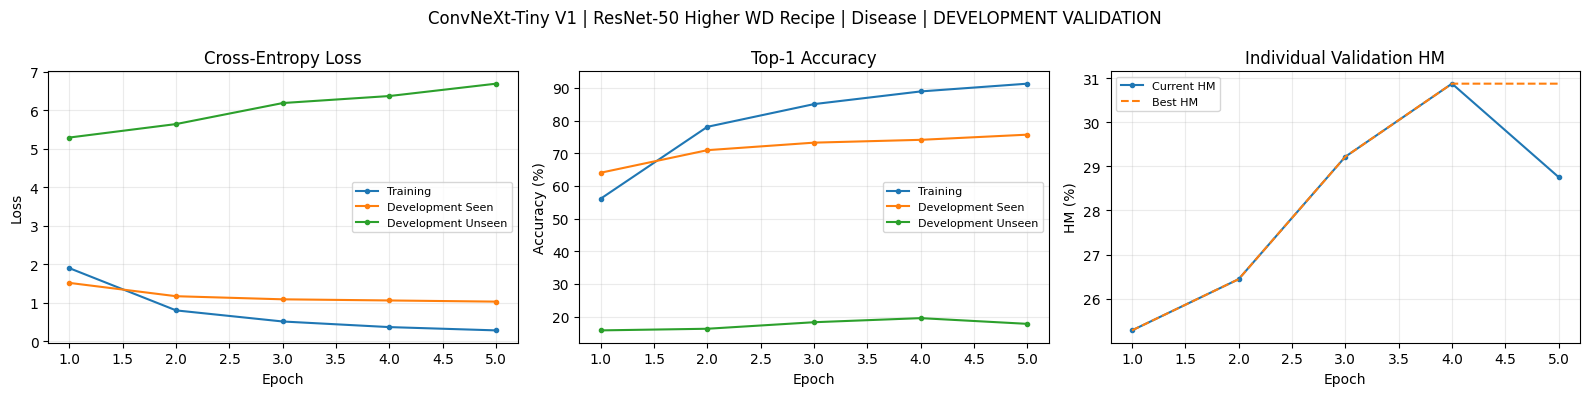

DISEASE Epoch 5/5: Train=91.30%, Dev Seen=75.68%, Dev Unseen=17.75%, HM=28.76%; Best HM=30.88% (epoch 4)


In [ ]:
train_to_epoch('crop', 5)
train_to_epoch('disease', 5)


## 10. Composition Evaluation

Combine the selected Crop and Disease predictions using their log probabilities.

Composition Accuracy is calculated over all 9,625 crop–disease pairs. Seen and unseen Composition Accuracy are then combined using the harmonic mean.


In [ ]:
def composition_metrics_from_saved():
    crop_file = run_dir('crop')/'best_validation.npz'
    disease_file = run_dir('disease')/'best_validation.npz'
    assert crop_file.exists() and disease_file.exists(), 'Missing task predictions'
    output = {}
    with np.load(crop_file) as crop, np.load(disease_file) as disease:
        for split, table in [('seen', val_seen_df), ('unseen', val_unseen_df)]:
            crop_log, disease_log = crop[split], disease[split]
            assert crop_log.shape == (len(table), 55)
            assert disease_log.shape == (len(table), 175)
            score = crop_log[:, :, None] + disease_log[:, None, :]
            prediction = score.reshape(len(table), 9625).argmax(axis=1)
            predicted_crop = np.array(crop_ids)[prediction // 175]
            predicted_disease = np.array(disease_ids)[prediction % 175]
            output[split] = {
                'composition_top1': float(np.mean((predicted_crop == table.crop_id.to_numpy()) &
                                                  (predicted_disease == table.disease_id.to_numpy()))),
                'crop_top1': float(np.mean(crop_log.argmax(1) ==
                           np.array([crop_index[int(x)] for x in table.crop_id]))),
                'disease_top1': float(np.mean(disease_log.argmax(1) ==
                              np.array([disease_index[int(x)] for x in table.disease_id]))),
            }
    output['composition_hm'] = harmonic(output['seen']['composition_top1'],
                                        output['unseen']['composition_top1'])
    return output


metrics=composition_metrics_from_saved()
results={'experiment':EXPERIMENT,'backbone':'ConvNeXt-Tiny',
         'weights':'IMAGENET1K_V1','selection':'individual_dev_hm',
         'candidate_pairs':9625,'stage':'STAGE1_DEVELOPMENT_ONLY',**metrics}
save_json(results,RESULTS_ROOT/'development_composition_metrics.json')
for task in ('crop','disease'):
    hist=pd.read_csv(run_dir(task)/'history.csv')
    print(f'{task}: best individual Development HM = {hist.individual_h.max():.2%} '
          f'at epoch {int(hist.loc[hist.individual_h.idxmax(),"epoch"])}')
print('Development Composition Seen:',f'{metrics["seen"]["composition_top1"]:.2%}')
print('Development Composition Unseen:',f'{metrics["unseen"]["composition_top1"]:.2%}')
print('Development Composition HM:',f'{metrics["composition_hm"]:.2%}')
display(pd.DataFrame([{'task':'composition','seen (%)':100*metrics['seen']['composition_top1'],
                        'unseen (%)':100*metrics['unseen']['composition_top1'],
                        'HM (%)':100*metrics['composition_hm']}]))
print('Saved in:',RESULTS_ROOT)

crop: best individual Development HM = 80.35% at epoch 5
disease: best individual Development HM = 30.88% at epoch 4
Development Composition Seen: 70.65%
Development Composition Unseen: 5.25%
Development Composition HM: 9.77%


,task,seen (%),unseen (%),HM (%)
0,composition,70.647482,5.25,9.773691


Saved in: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD


In [ ]:
def report_phase(phase):
    assert phase in (5, 15, 30)
    m = composition_metrics_from_saved()
    record = {'phase_target_epochs':phase, 'stage':'STAGE1_DEVELOPMENT_ONLY',
              'composition_seen':m['seen']['composition_top1'],
              'composition_unseen':m['unseen']['composition_top1'],
              'composition_hm':m['composition_hm']}
    for task in ('crop','disease'):
        h = pd.read_csv(run_dir(task)/'history.csv')
        assert len(h)>=phase and int(h.epoch.max())>=phase, f'{task} has not reached epoch {phase}'
        h = h[h.epoch <= phase]
        row=h.loc[h.individual_h.idxmax()]
        record[f'{task}_selected_epoch']=int(row.epoch)
        record[f'{task}_best_seen']=float(row.seen_acc)
        record[f'{task}_best_unseen']=float(row.unseen_acc)
        record[f'{task}_best_hm']=float(row.individual_h)
    # These are the best checkpoints as of this phase, not reselected from official test.
    save_json(record,RESULTS_ROOT/f'phase_{phase:02d}_development_metrics.json')
    file=RESULTS_ROOT/'phase_summary.csv'
    if file.exists():
        old=pd.read_csv(file)
        old=old[old.phase_target_epochs != phase]
        pd.concat([old,pd.DataFrame([record])],ignore_index=True).sort_values('phase_target_epochs').to_csv(file,index=False)
    else:
        pd.DataFrame([record]).to_csv(file,index=False)
    display(pd.DataFrame([record]).round(4))
    print('Snapshot saved:',RESULTS_ROOT/f'phase_{phase:02d}_development_metrics.json')

report_phase(5)

,phase_target_epochs,stage,composition_seen,composition_unseen,composition_hm,crop_selected_epoch,crop_best_seen,crop_best_unseen,crop_best_hm,disease_selected_epoch,disease_best_seen,disease_best_unseen,disease_best_hm
0,5,STAGE1_DEVELOPMENT_ONLY,0.7324,0.07,0.1278,5,0.8935,0.73,0.8035,4,0.741,0.195,0.3088


Snapshot saved: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/phase_05_development_metrics.json



## 11. Extended Training — Epochs 6–15

Continue training from the saved Epoch 5 checkpoints. The original 30-epoch learning rate schedule is maintained without restarting.


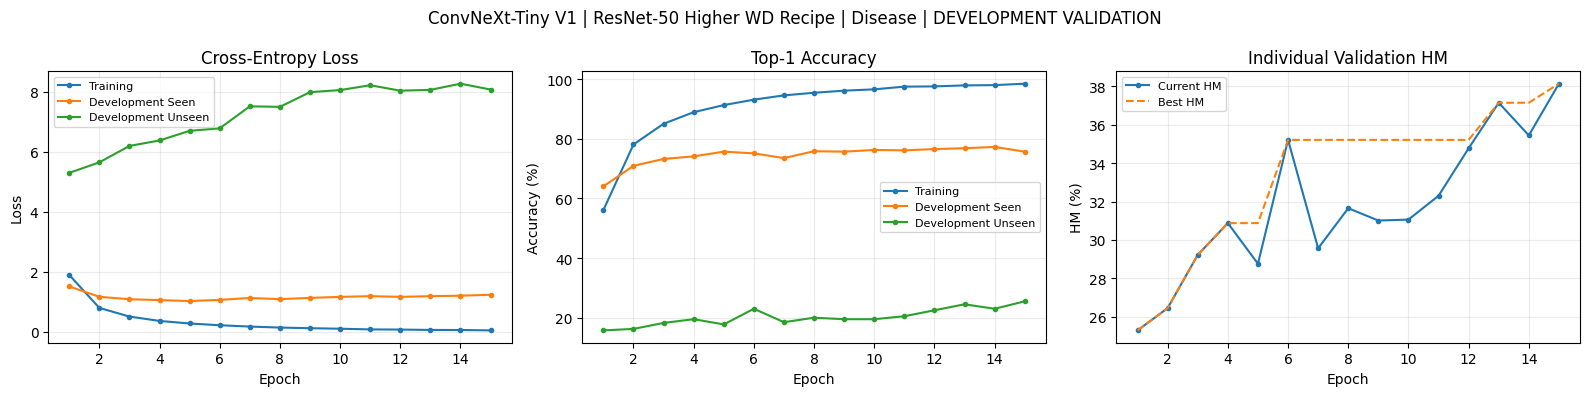

DISEASE Epoch 15/15: Train=98.48%, Dev Seen=75.68%, Dev Unseen=25.50%, HM=38.15%; Best HM=38.15% (epoch 15)


,phase_target_epochs,stage,composition_seen,composition_unseen,composition_hm,crop_selected_epoch,crop_best_seen,crop_best_unseen,crop_best_hm,disease_selected_epoch,disease_best_seen,disease_best_unseen,disease_best_hm
0,15,STAGE1_DEVELOPMENT_ONLY,0.7324,0.07,0.1278,13,0.905,0.735,0.8112,15,0.7568,0.255,0.3815


Snapshot saved: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/phase_15_development_metrics.json


In [ ]:
CONTINUE_TO_15 = True

if CONTINUE_TO_15:
    train_to_epoch('crop', 15)
    train_to_epoch('disease', 15)
    report_phase(15)
else:
    print('Stopped at Epoch 5. To continue: set CONTINUE_TO_15=True and run this cell.')


## 12. Final Stage 1 Training — Epochs 16–30

Extend both models to 30 epochs and retain the checkpoints with the highest individual development validation HM.

All previous epoch checkpoints remain available for further analysis.


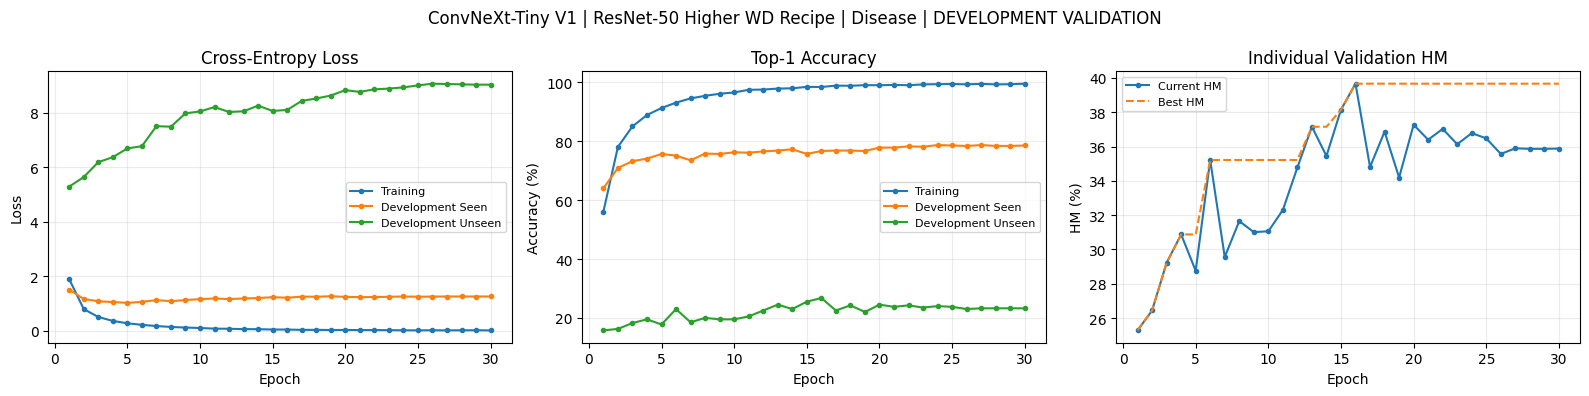

DISEASE Epoch 30/30: Train=99.57%, Dev Seen=78.56%, Dev Unseen=23.25%, HM=35.88%; Best HM=39.66% (epoch 16)


,phase_target_epochs,stage,composition_seen,composition_unseen,composition_hm,crop_selected_epoch,crop_best_seen,crop_best_unseen,crop_best_hm,disease_selected_epoch,disease_best_seen,disease_best_unseen,disease_best_hm
0,30,STAGE1_DEVELOPMENT_ONLY,0.7453,0.07,0.128,29,0.9165,0.74,0.8189,16,0.7669,0.2675,0.3966


Snapshot saved: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/phase_30_development_metrics.json


In [ ]:
CONTINUE_TO_30 = True

if CONTINUE_TO_30:
    for task in ('crop','disease'):
        history_file = run_dir(task)/'history.csv'
        assert history_file.exists() and int(pd.read_csv(history_file).epoch.max()) >= 15, (
            f'{task} must complete Epoch 15 before the Epoch 30 gate'
        )
    train_to_epoch('crop', 30)
    train_to_epoch('disease', 30)
    report_phase(30)
else:
    print('Epoch 30 continuation disabled. Set CONTINUE_TO_30=True after Phase 15 review.')


## 13. Stage 1 Development Results

Compare the development results from the 5-, 15- and 30-epoch training phases.

The final Stage 1 checkpoints are selected independently for Crop and Disease based on their highest validation HM.


In [ ]:
phase_file=RESULTS_ROOT/'phase_summary.csv'
if phase_file.exists():
    display(pd.read_csv(phase_file).round(4))
    print('Saved summaries:',phase_file)
else:
    print('No completed phase summary yet.')

,phase_target_epochs,stage,composition_seen,composition_unseen,composition_hm,crop_selected_epoch,crop_best_seen,crop_best_unseen,crop_best_hm,disease_selected_epoch,disease_best_seen,disease_best_unseen,disease_best_hm
0,5,STAGE1_DEVELOPMENT_ONLY,0.7324,0.07,0.1278,5,0.8935,0.730,0.8035,4,0.7410,0.1950,0.3088
1,15,STAGE1_DEVELOPMENT_ONLY,0.7324,0.07,0.1278,13,0.9050,0.735,0.8112,15,0.7568,0.2550,0.3815
2,30,STAGE1_DEVELOPMENT_ONLY,0.7453,0.07,0.1280,29,0.9165,0.740,0.8189,16,0.7669,0.2675,0.3966


Saved summaries: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/phase_summary.csv


In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

ROOT = Path(
    "/content/drive/MyDrive/"
    "AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD"
)

df = pd.read_csv(ROOT / "phase_summary.csv")

# Display percentages without changing saved data
display_df = df.copy()

percent_cols = [
    "composition_seen",
    "composition_unseen",
    "composition_hm",
    "crop_best_seen",
    "crop_best_unseen",
    "crop_best_hm",
    "disease_best_seen",
    "disease_best_unseen",
    "disease_best_hm"
]

for col in percent_cols:
    display_df[col] = display_df[col].map(
        lambda x: f"{x * 100:.2f}%"
    )

print("CONVNEXT-TINY — DEVELOPMENT RESULTS")
display(display_df)


CONVNEXT-TINY — DEVELOPMENT RESULTS


,phase_target_epochs,stage,composition_seen,composition_unseen,composition_hm,crop_selected_epoch,crop_best_seen,crop_best_unseen,crop_best_hm,disease_selected_epoch,disease_best_seen,disease_best_unseen,disease_best_hm
0,5,STAGE1_DEVELOPMENT_ONLY,73.24%,7.00%,12.78%,5,89.35%,73.00%,80.35%,4,74.10%,19.50%,30.88%
1,15,STAGE1_DEVELOPMENT_ONLY,73.24%,7.00%,12.78%,13,90.50%,73.50%,81.12%,15,75.68%,25.50%,38.15%
2,30,STAGE1_DEVELOPMENT_ONLY,74.53%,7.00%,12.80%,29,91.65%,74.00%,81.89%,16,76.69%,26.75%,39.66%



### Selected Stage 1 Checkpoints

| Model | Selected Epoch | Seen Accuracy | Unseen Accuracy | HM |
|---|---:|---:|---:|---:|
| Crop CNN | 29 | 91.65% | 74.00% | 81.89% |
| Disease CNN | 16 | 76.69% | 26.75% | 39.66% |

**Composition Results:** Seen 74.53%, Unseen 7.00%, HM 12.80%.

These selected checkpoints are used to initialise Stage 2 full-data fine-tuning.



# Stage 2 — Full-Data Fine-Tuning

Stage 2 continues training from the selected Stage 1 Crop and Disease checkpoints.

All 8,000 original training images are used, with reduced learning rates for more conservative fine-tuning. No independent validation set is used during this stage.

The highest training accuracy is used as the predefined Stage 2 checkpoint selection criterion. This does not guarantee the best unseen generalisation.



## 14. Full Training Dataset Preparation

Load and verify all 8,000 original training images, ensuring they match the combined Stage 1 development data.

Load the selected Stage 1 checkpoints and configure Stage 2 with the following settings:

| Hyperparameter | Value |
|---|---|
| Backbone Learning Rate | 1e-6 |
| Classification Head Learning Rate | 1e-4 |
| Weight Decay | 1e-3 |
| Batch Size | 16 |
| Fine-Tuning Epochs | 10 |


In [ ]:

# ============================================================
# STAGE 2 — CELL 1
# Prepare Full 8,000 Training Dataset
# No official test access
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import json
import shutil
import gc
import time
import copy
import os

STAGE2_ROOT = RESULTS_ROOT / "stage2_full8000"
STAGE2_ROOT.mkdir(parents=True, exist_ok=True)

STAGE2_EPOCHS = 10
STAGE2_BACKBONE_LR = 1e-6
STAGE2_HEAD_LR = 1e-4
STAGE2_WEIGHT_DECAY = 1e-3

# Original training CSV has no header
CSV_COLUMNS = [
    "filename", "crop_id", "disease_id",
    "composition_id", "crop_name",
    "disease_name", "composition_name"
]

full_csv = LOCAL_PROJECT / "DPD_Small_train.csv"

if not full_csv.exists():
    source = DRIVE_PROJECT / "DPD_Small_train.csv"
    assert source.exists(), f"Missing: {source}"
    shutil.copy2(source, full_csv)

with open(full_csv, encoding="utf-8-sig") as f:
    first = f.readline().split(",")[0].strip().lower()

full_train_df = pd.read_csv(
    full_csv,
    header=0 if first == "filename" else None,
    names=CSV_COLUMNS,
    encoding="utf-8-sig"
)

for col in ("crop_id", "disease_id", "composition_id"):
    full_train_df[col] = pd.to_numeric(
        full_train_df[col], errors="raise"
    ).astype(int)

assert len(full_train_df) == 8000
assert full_train_df.filename.is_unique

# Full training must equal Stage 1 train + both validation sets
expected_files = (
    set(train_df.filename)
    | set(val_seen_df.filename)
    | set(val_unseen_df.filename)
)

assert set(full_train_df.filename) == expected_files
assert len(expected_files) == 8000

assert set(full_train_df.crop_id) == set(crop_ids)
assert set(full_train_df.disease_id) == set(disease_ids)

missing_images = (
    set(full_train_df.filename) - set(image_lookup)
)
assert not missing_images, (
    f"Missing images: {list(missing_images)[:5]}"
)

print("=" * 60)
print("CONVNEXT-TINY — STAGE 2 DATA VERIFICATION")
print("=" * 60)
print("Stage 1 Training:", len(train_df))
print("Stage 1 Seen Validation:", len(val_seen_df))
print("Stage 1 Unseen Validation:", len(val_unseen_df))
print("Stage 2 Full Training:", len(full_train_df))
print("Crop Classes:", len(crop_ids))
print("Disease Classes:", len(disease_ids))
print("Data Integrity: PASS")
print("Official Test: NOT USED")

# Check Stage 1 selected checkpoints
for task in ("crop", "disease"):
    best_path = run_dir(task) / "best.pt"
    assert best_path.exists(), f"Missing: {best_path}"

    ckpt = torch.load(
        best_path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["task"] == task
    assert ckpt["backbone"] == "convnext_tiny"
    assert ckpt["pretrained_weights"] == "IMAGENET1K_V1"
    assert ckpt["fine_tuning"] == "full"
    assert list(ckpt["crop_ids"]) == list(crop_ids)
    assert list(ckpt["disease_ids"]) == list(disease_ids)

    print(
        f"{task.upper()} Stage 1 selected Epoch:",
        ckpt["epoch"]
    )

    del ckpt

print("\nStage 2 output:", STAGE2_ROOT)


CONVNEXT-TINY — STAGE 2 DATA VERIFICATION
Stage 1 Training: 6905
Stage 1 Seen Validation: 695
Stage 1 Unseen Validation: 400
Stage 2 Full Training: 8000
Crop Classes: 55
Disease Classes: 175
Data Integrity: PASS
Official Test: NOT USED
CROP Stage 1 selected Epoch: 29
DISEASE Stage 1 selected Epoch: 16

Stage 2 output: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage2_full8000



## 15. Full-Data Fine-Tuning Functions

Define the Stage 2 training procedure, checkpoint recovery, and training curve visualisation.

Each model is fine-tuned independently for 10 additional epochs. Checkpoints and training histories are saved after every epoch.


In [ ]:

# ============================================================
# STAGE 2 — CELL 2
# Full-Data Fine-Tuning with Recovery
# Save Every Epoch + Training History + Graph
# ============================================================

import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

def stage2_dir(task):
    return STAGE2_ROOT / task


def stage2_config(task, source_ckpt):
    return {
        "task": task,
        "backbone": "convnext_tiny",
        "weights": "IMAGENET1K_V1",
        "strategy": "full",
        "stage": 2,
        "source_epoch": int(source_ckpt["epoch"]),
        "source_stage1_path": str(
            run_dir(task) / "best.pt"
        ),
        "backbone_lr": STAGE2_BACKBONE_LR,
        "head_lr": STAGE2_HEAD_LR,
        "weight_decay": STAGE2_WEIGHT_DECAY,
        "dropout": float(
            source_ckpt["config"]["dropout"]
        ),
        "epochs": STAGE2_EPOCHS,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
        "scheduler": "CosineAnnealingLR(T_max=10)",
        "selection": "highest_training_accuracy",
        "validation": "none_full_data_training",
        "training_images": 8000
    }


def plot_stage2_history(history, task, folder):
    df = pd.DataFrame(history)

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 4)
    )

    axes[0].plot(
        df["epoch"], df["train_loss"], marker="o"
    )
    axes[0].set_title(f"{task.title()} Training Loss")
    axes[0].set_xlabel("Stage 2 Epoch")
    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        df["epoch"],
        df["train_acc"] * 100,
        marker="o"
    )
    axes[1].set_title(f"{task.title()} Training Accuracy")
    axes[1].set_xlabel("Stage 2 Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].set_ylim(0, 100)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()

    # Overwrite the cumulative graph, not model checkpoints
    fig.savefig(
        folder / "stage2_training_curves.png",
        dpi=160,
        bbox_inches="tight"
    )

    # Do not clear previous Colab output
    display(fig)
    plt.close(fig)


def train_stage2(task):
    assert task in ("crop", "disease")
    assert DEVICE.type == "cuda"

    folder = stage2_dir(task)
    folder.mkdir(parents=True, exist_ok=True)

    source_path = run_dir(task) / "best.pt"

    source = torch.load(
        source_path,
        map_location="cpu",
        weights_only=False
    )

    assert source["task"] == task
    assert source["fine_tuning"] == "full"
    assert source["backbone"] == "convnext_tiny"

    cfg = stage2_config(task, source)

    config_path = folder / "config.json"
    resume_path = folder / "resume_state.pt"
    history_path = folder / "history.csv"
    best_path = folder / "best_train_acc.pt"

    # Protect existing experiments from config changes
    if config_path.exists():
        saved_cfg = json.loads(
            config_path.read_text(encoding="utf-8")
        )
        assert saved_cfg == cfg, (
            f"Stage 2 config mismatch: {folder}"
        )
    else:
        assert not any(folder.iterdir()), (
            f"Unknown existing files in {folder}"
        )
        save_json(cfg, config_path)

    # Check whether training already finished
    if resume_path.exists():
        state = torch.load(
            resume_path,
            map_location="cpu",
            weights_only=False
        )

        assert state["config"] == cfg
        assert state["task"] == task

        if int(state["epoch"]) >= STAGE2_EPOCHS:
            assert best_path.exists()
            assert history_path.exists()
            print(
                f"{task.upper()} already completed "
                f"{STAGE2_EPOCHS} epochs. Skipping."
            )
            return
    else:
        assert not history_path.exists(), (
            "History exists without resume state. "
            "Manual recovery required."
        )
        assert not best_path.exists(), (
            "Best checkpoint exists without resume state."
        )

    seed_all(SEED)

    # Build exact same ConvNeXt architecture as Stage 1
    # pretrained=False prevents reinitializing from ImageNet
    model = build_model(
        task,
        cfg["dropout"],
        pretrained=False
    )

    # Default Stage 2 starts from Stage 1 best
    model.load_state_dict(
        source["state_dict"],
        strict=True
    )

    optimizer = torch.optim.AdamW(
        [
            {
                "params": [
                    p for name, p in model.named_parameters()
                    if not name.startswith("classifier.")
                ],
                "lr": STAGE2_BACKBONE_LR
            },
            {
                "params": [
                    p for name, p in model.named_parameters()
                    if name.startswith("classifier.")
                ],
                "lr": STAGE2_HEAD_LR
            }
        ],
        weight_decay=STAGE2_WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=STAGE2_EPOCHS
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP
    )

    history = []
    best_acc = -1.0
    best_epoch = 0
    first_epoch = 1

    # Resume exact optimizer/scheduler/model state
    if resume_path.exists():
        model.load_state_dict(
            state["model_state"], strict=True
        )

        optimizer.load_state_dict(
            state["optimizer_state"]
        )
        scheduler.load_state_dict(
            state["scheduler_state"]
        )
        scaler.load_state_dict(
            state["scaler_state"]
        )

        history = state["history"]
        best_acc = float(state["best_acc"])
        best_epoch = int(state["best_epoch"])
        first_epoch = int(state["epoch"]) + 1

        restore_rng(state["rng"])

        print(
            f"Resuming {task.upper()} "
            f"from Stage 2 Epoch {first_epoch}"
        )

        del state

    else:
        print(
            f"Starting {task.upper()} Stage 2 "
            f"from Stage 1 Epoch {source['epoch']}"
        )

    del source

    # Full 8000 images, same Stage 1 augmentation
    loader = make_loader(
        full_train_df,
        training=True,
        batch_size=BATCH_SIZE
    )

    try:
        for epoch in range(
            first_epoch,
            STAGE2_EPOCHS + 1
        ):
            start = time.time()

            # Use existing Stage 1 training function
            result = train_epoch(
                model,
                loader,
                task,
                optimizer,
                scaler,
                f"Stage2 {task} {epoch}/{STAGE2_EPOCHS}"
            )

            train_loss = float(result["loss"])
            train_acc = float(result["top1"])

            # Save model weights every epoch
            model_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            checkpoint = {
                "state_dict": model_state,
                "task": task,
                "stage": 2,
                "backbone": "convnext_tiny",
                "pretrained_weights": "IMAGENET1K_V1",
                "fine_tuning": "full",
                "epoch": epoch,
                "source_stage1_epoch": cfg["source_epoch"],
                "config": cfg,
                "crop_ids": crop_ids,
                "disease_ids": disease_ids,
                "selection_metric": "highest_training_accuracy",
                "train_acc": train_acc,
                "train_loss": train_loss
            }

            epoch_path = folder / f"epoch_{epoch:02d}.pt"

            atomic_torch_save(
                checkpoint,
                epoch_path
            )

            # Select task checkpoints independently
            if train_acc > best_acc + 1e-12:
                best_acc = train_acc
                best_epoch = epoch

                shutil.copy2(
                    epoch_path,
                    best_path
                )

            history.append({
                "epoch": epoch,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "best_train_acc": best_acc,
                "best_epoch": best_epoch,
                "seconds": time.time() - start
            })

            scheduler.step()

            # Save full recovery state after each epoch
            atomic_torch_save(
                {
                    "task": task,
                    "config": cfg,
                    "epoch": epoch,
                    "history": copy.deepcopy(history),
                    "best_acc": best_acc,
                    "best_epoch": best_epoch,
                    "model_state": model_state,
                    "optimizer_state": optimizer.state_dict(),
                    "scheduler_state": scheduler.state_dict(),
                    "scaler_state": scaler.state_dict(),
                    "rng": capture_rng()
                },
                resume_path
            )

            pd.DataFrame(history).to_csv(
                history_path,
                index=False
            )

            print("\n" + "=" * 55)
            print(
                f"{task.upper()} — "
                f"STAGE 2 EPOCH {epoch}/{STAGE2_EPOCHS}"
            )
            print("=" * 55)
            print(f"Train Loss: {train_loss:.4f}")
            print(f"Train Accuracy: {train_acc:.2%}")
            print(
                f"Highest Training Accuracy: "
                f"{best_acc:.2%} (Epoch {best_epoch})"
            )
            print("Checkpoint:", epoch_path.name)

            # Keep all epoch summaries and plots in output
            plot_stage2_history(
                history, task, folder
            )

    finally:
        del model, optimizer, scheduler, scaler, loader
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print(f"\n{task.upper()} STAGE 2 COMPLETED")
    print("Results:", folder)



## 16. Execute Stage 2 Fine-Tuning

Run full-data fine-tuning for both Crop and Disease CNNs.

The final checkpoints are selected independently using the highest training accuracy and saved for Official Test Evaluation.


CONVNEXT-TINY — STAGE 2 FULL-DATA FINE-TUNING
Starting CROP Stage 2 from Stage 1 Epoch 29


Stage2 crop 1/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 1/10
Train Loss: 0.1541
Train Accuracy: 97.76%
Highest Training Accuracy: 97.76% (Epoch 1)
Checkpoint: epoch_01.pt


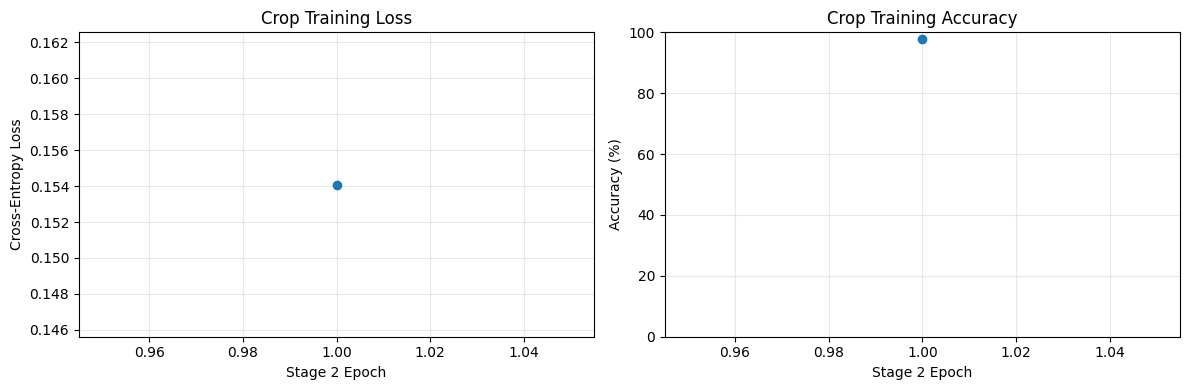

Stage2 crop 2/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 2/10
Train Loss: 0.0797
Train Accuracy: 98.40%
Highest Training Accuracy: 98.40% (Epoch 2)
Checkpoint: epoch_02.pt


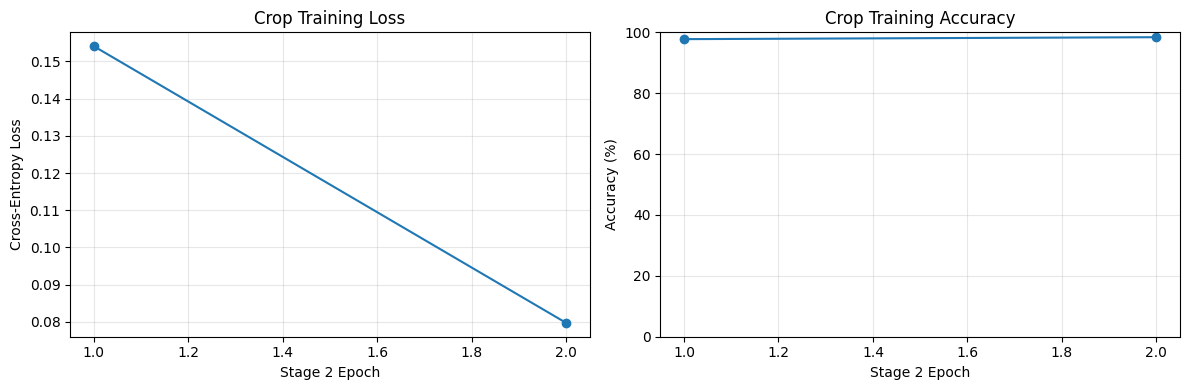

Stage2 crop 3/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 3/10
Train Loss: 0.0583
Train Accuracy: 98.62%
Highest Training Accuracy: 98.62% (Epoch 3)
Checkpoint: epoch_03.pt


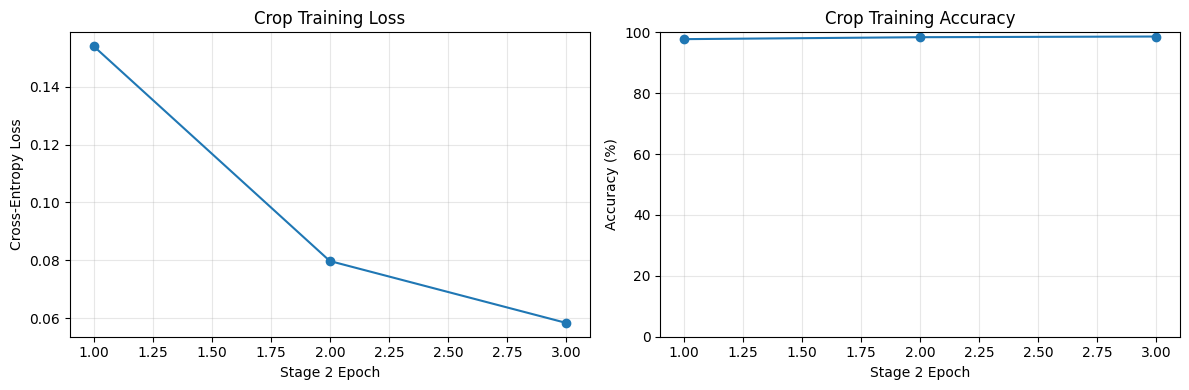

Stage2 crop 4/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 4/10
Train Loss: 0.0442
Train Accuracy: 98.84%
Highest Training Accuracy: 98.84% (Epoch 4)
Checkpoint: epoch_04.pt


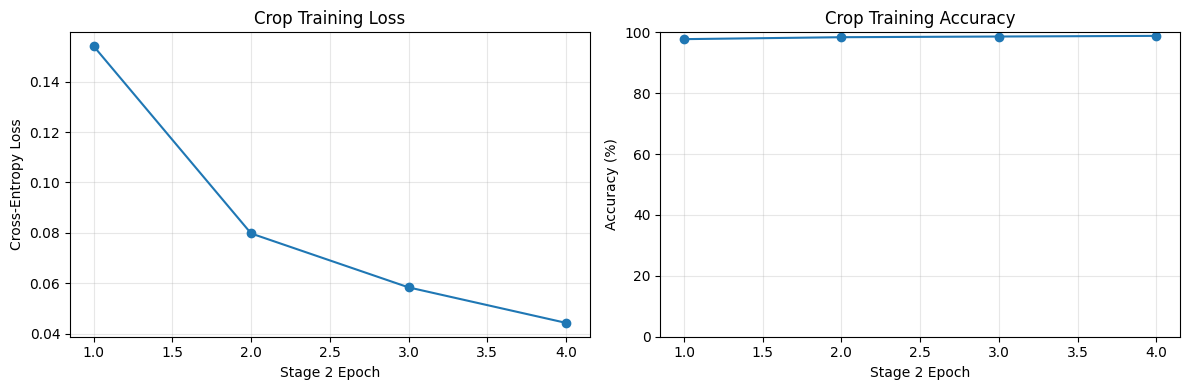

Stage2 crop 5/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 5/10
Train Loss: 0.0339
Train Accuracy: 99.15%
Highest Training Accuracy: 99.15% (Epoch 5)
Checkpoint: epoch_05.pt


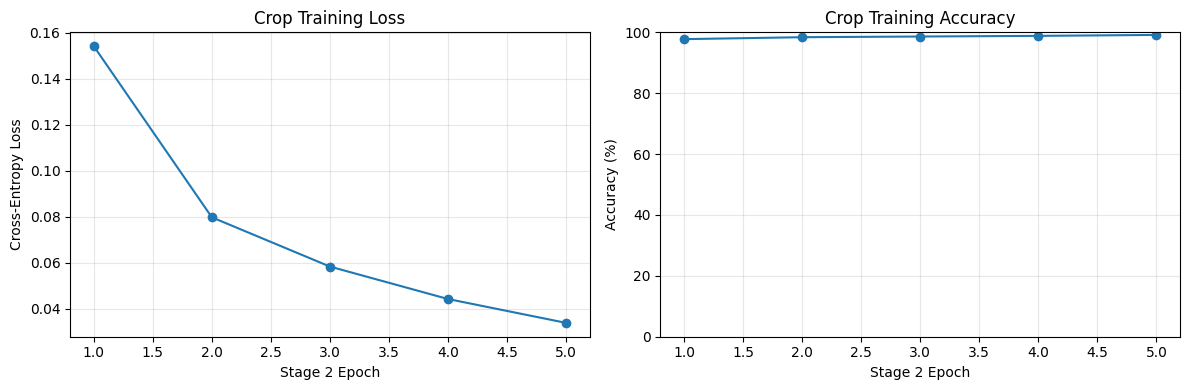

Stage2 crop 6/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 6/10
Train Loss: 0.0350
Train Accuracy: 99.09%
Highest Training Accuracy: 99.15% (Epoch 5)
Checkpoint: epoch_06.pt


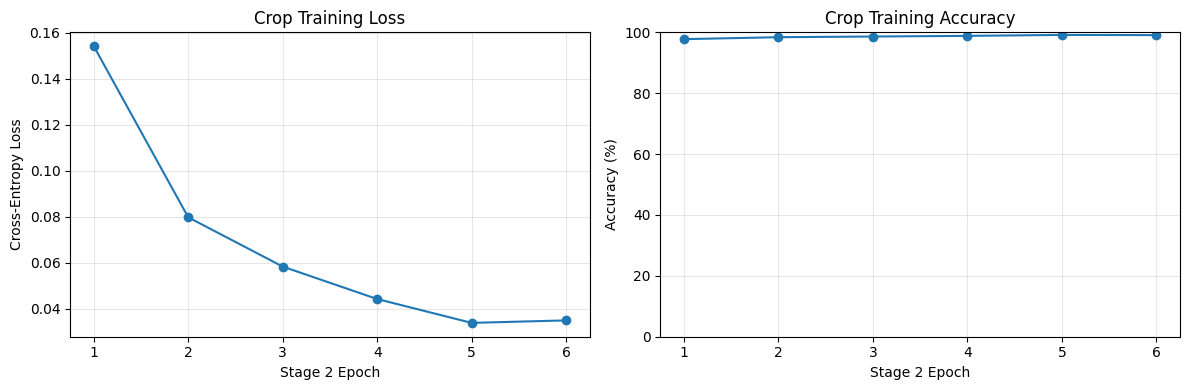

Stage2 crop 7/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 7/10
Train Loss: 0.0322
Train Accuracy: 99.21%
Highest Training Accuracy: 99.21% (Epoch 7)
Checkpoint: epoch_07.pt


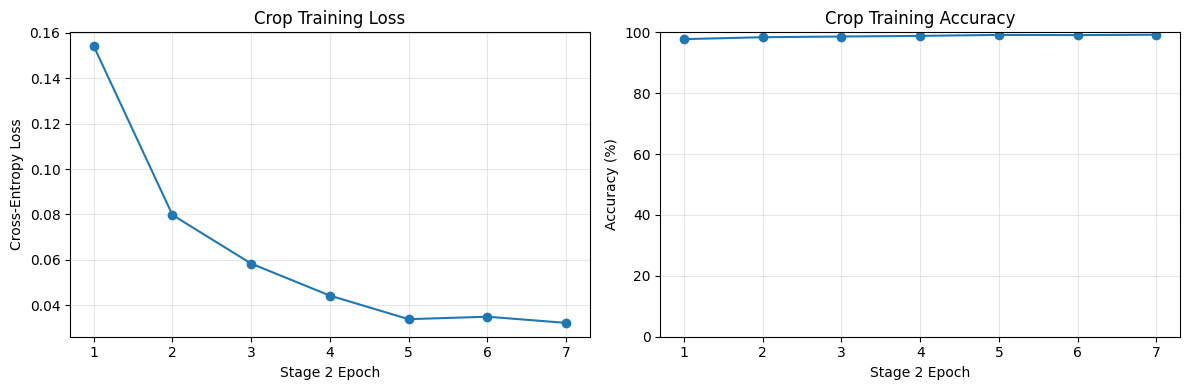

Stage2 crop 8/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 8/10
Train Loss: 0.0280
Train Accuracy: 99.24%
Highest Training Accuracy: 99.24% (Epoch 8)
Checkpoint: epoch_08.pt


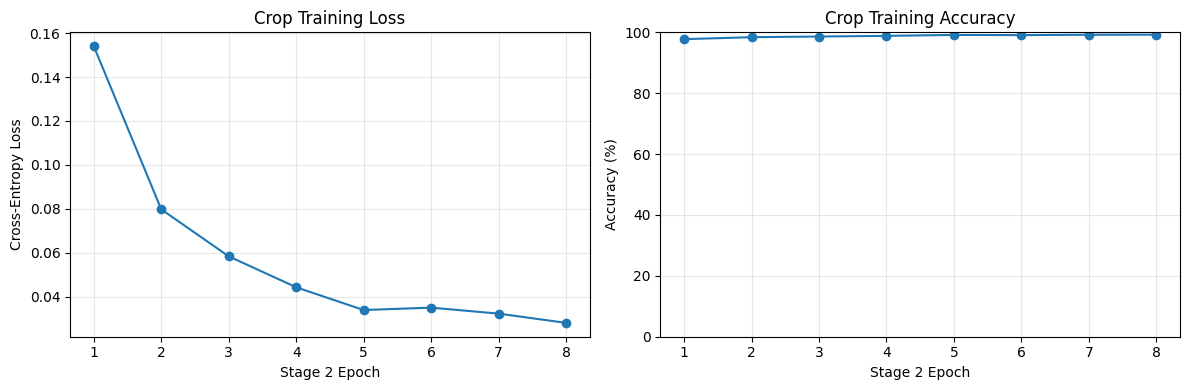

Stage2 crop 9/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 9/10
Train Loss: 0.0286
Train Accuracy: 99.28%
Highest Training Accuracy: 99.28% (Epoch 9)
Checkpoint: epoch_09.pt


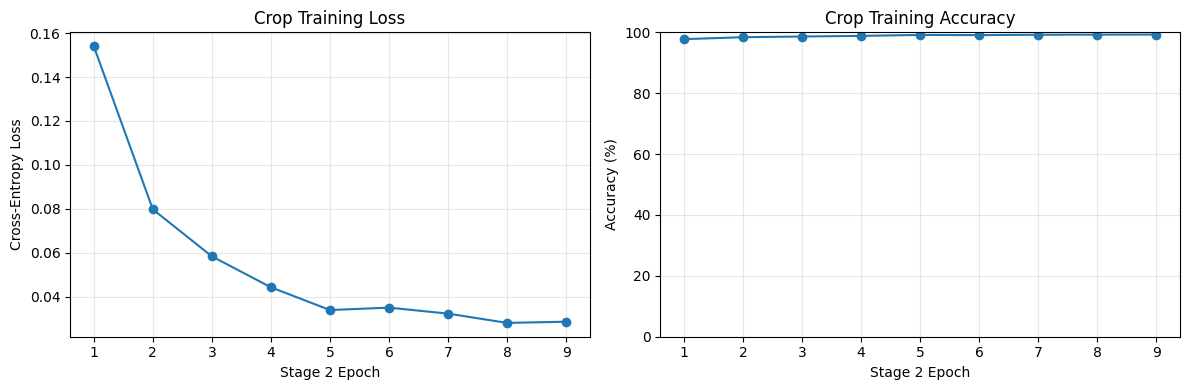

Stage2 crop 10/10:   0%|          | 0/500 [00:00<?, ?it/s]


CROP — STAGE 2 EPOCH 10/10
Train Loss: 0.0274
Train Accuracy: 99.26%
Highest Training Accuracy: 99.28% (Epoch 9)
Checkpoint: epoch_10.pt


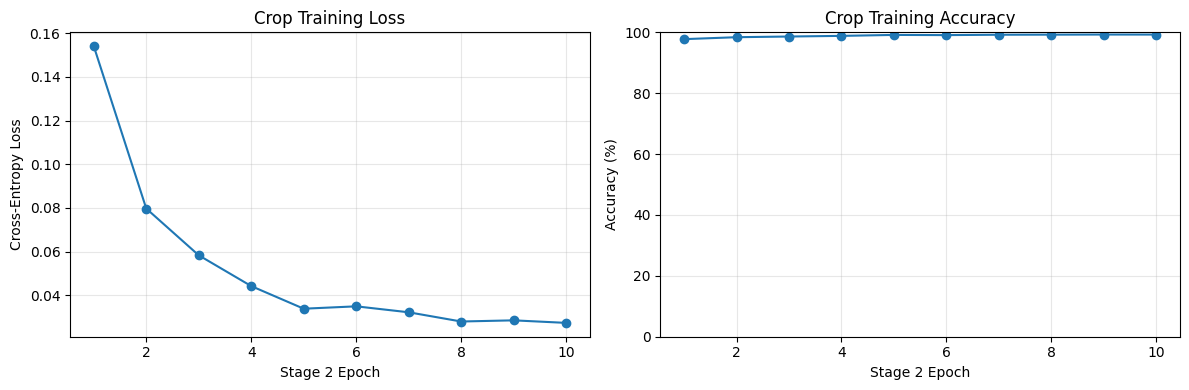


CROP STAGE 2 COMPLETED
Results: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage2_full8000/crop
Starting DISEASE Stage 2 from Stage 1 Epoch 16


Stage2 disease 1/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 1/10
Train Loss: 0.4308
Train Accuracy: 93.40%
Highest Training Accuracy: 93.40% (Epoch 1)
Checkpoint: epoch_01.pt


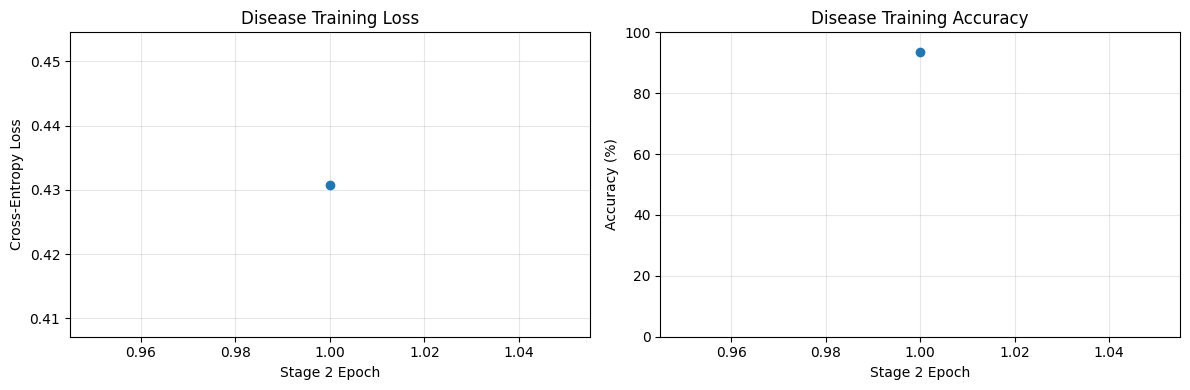

Stage2 disease 2/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 2/10
Train Loss: 0.2610
Train Accuracy: 94.23%
Highest Training Accuracy: 94.23% (Epoch 2)
Checkpoint: epoch_02.pt


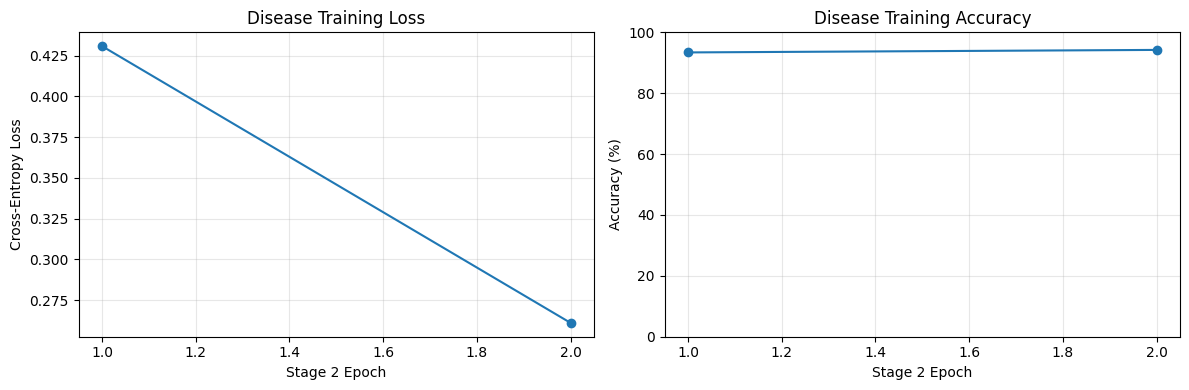

Stage2 disease 3/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 3/10
Train Loss: 0.2204
Train Accuracy: 94.50%
Highest Training Accuracy: 94.50% (Epoch 3)
Checkpoint: epoch_03.pt


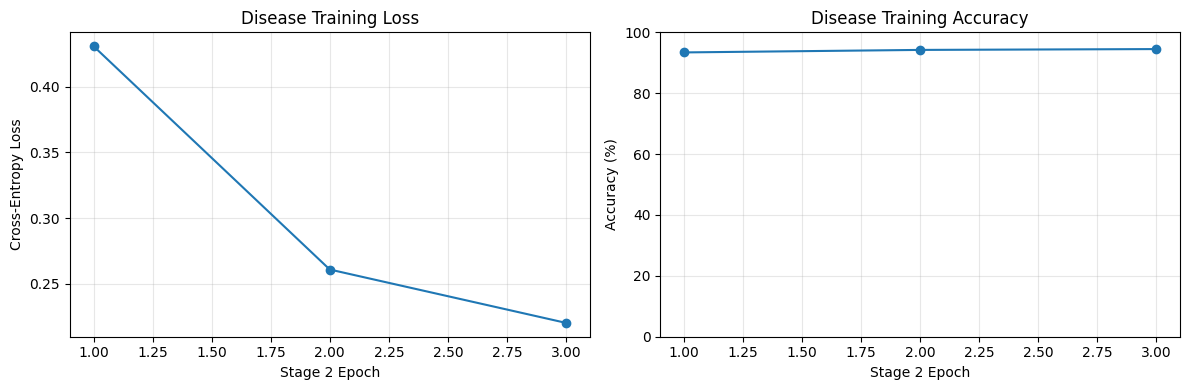

Stage2 disease 4/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 4/10
Train Loss: 0.1979
Train Accuracy: 94.79%
Highest Training Accuracy: 94.79% (Epoch 4)
Checkpoint: epoch_04.pt


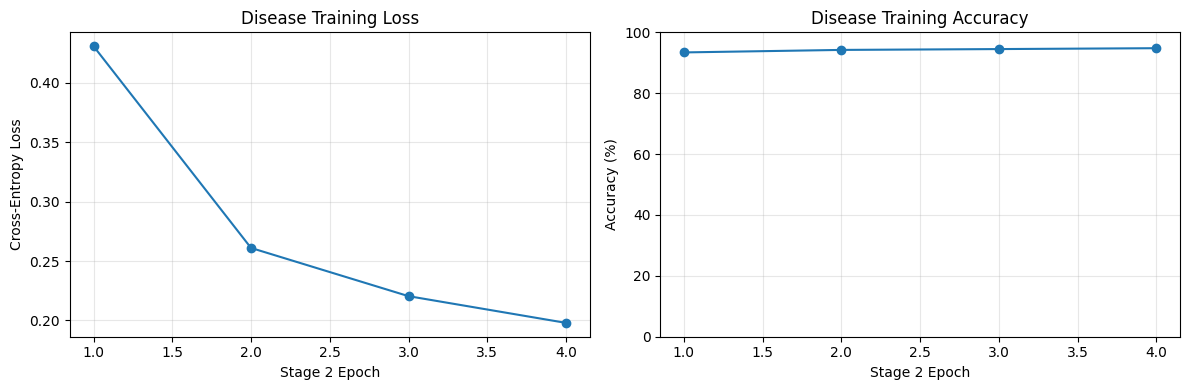

Stage2 disease 5/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 5/10
Train Loss: 0.1733
Train Accuracy: 95.61%
Highest Training Accuracy: 95.61% (Epoch 5)
Checkpoint: epoch_05.pt


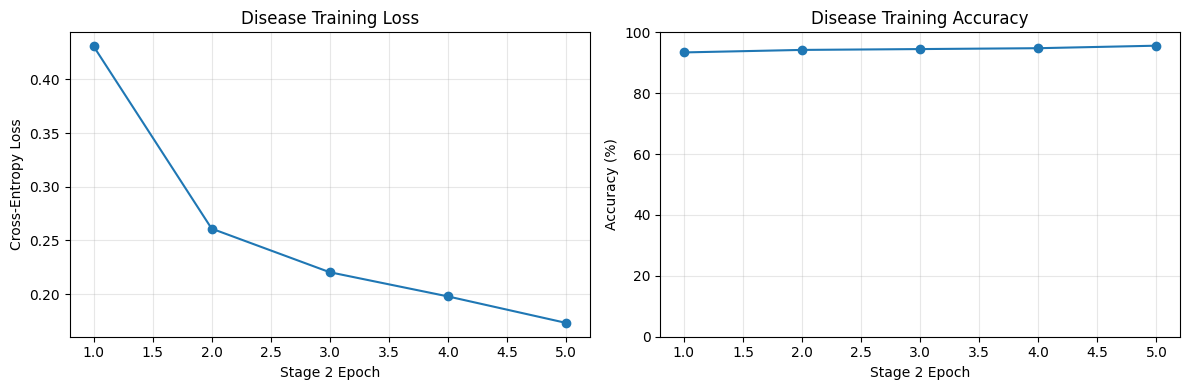

Stage2 disease 6/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 6/10
Train Loss: 0.1529
Train Accuracy: 95.86%
Highest Training Accuracy: 95.86% (Epoch 6)
Checkpoint: epoch_06.pt


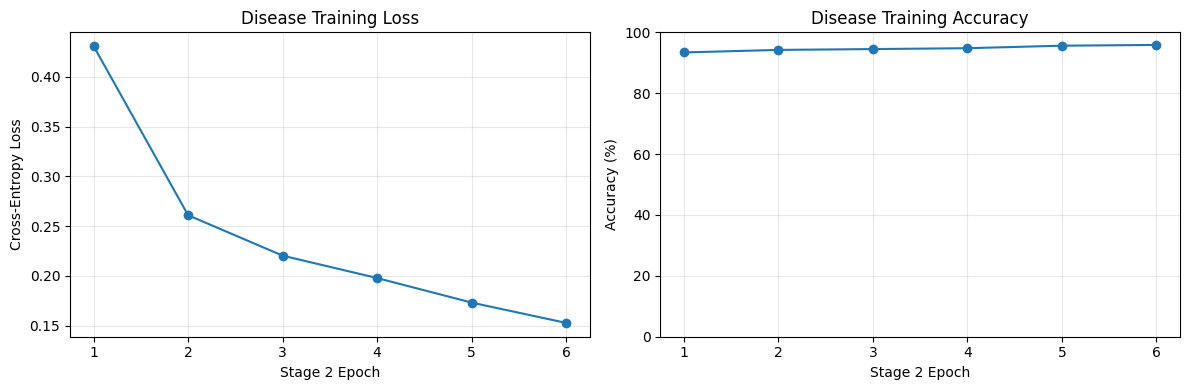

Stage2 disease 7/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 7/10
Train Loss: 0.1506
Train Accuracy: 95.88%
Highest Training Accuracy: 95.88% (Epoch 7)
Checkpoint: epoch_07.pt


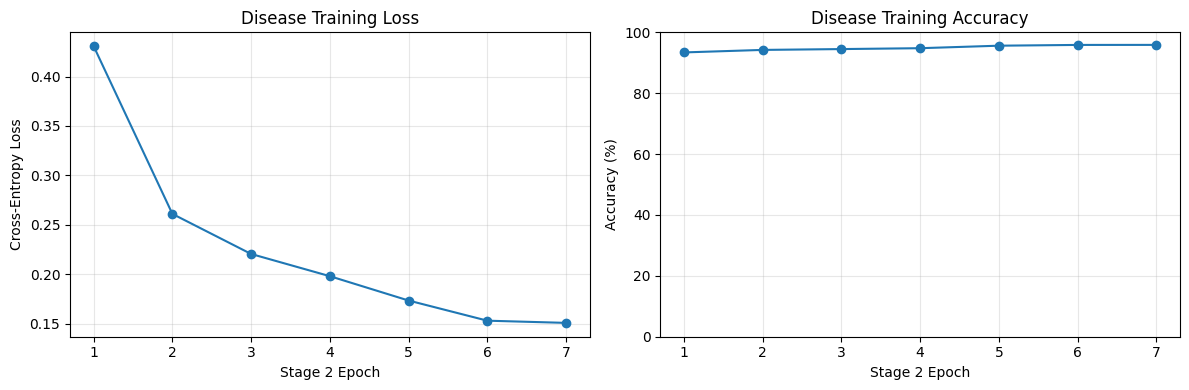

Stage2 disease 8/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 8/10
Train Loss: 0.1471
Train Accuracy: 95.93%
Highest Training Accuracy: 95.93% (Epoch 8)
Checkpoint: epoch_08.pt


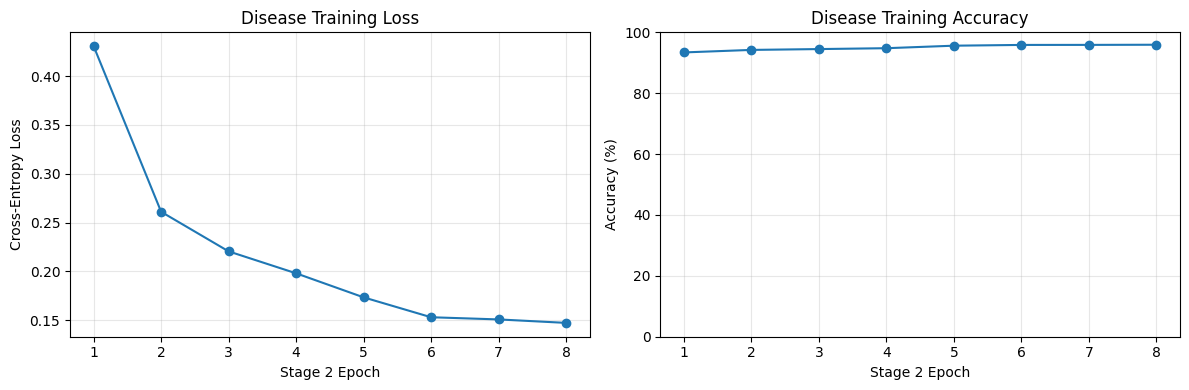

Stage2 disease 9/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 9/10
Train Loss: 0.1384
Train Accuracy: 96.20%
Highest Training Accuracy: 96.20% (Epoch 9)
Checkpoint: epoch_09.pt


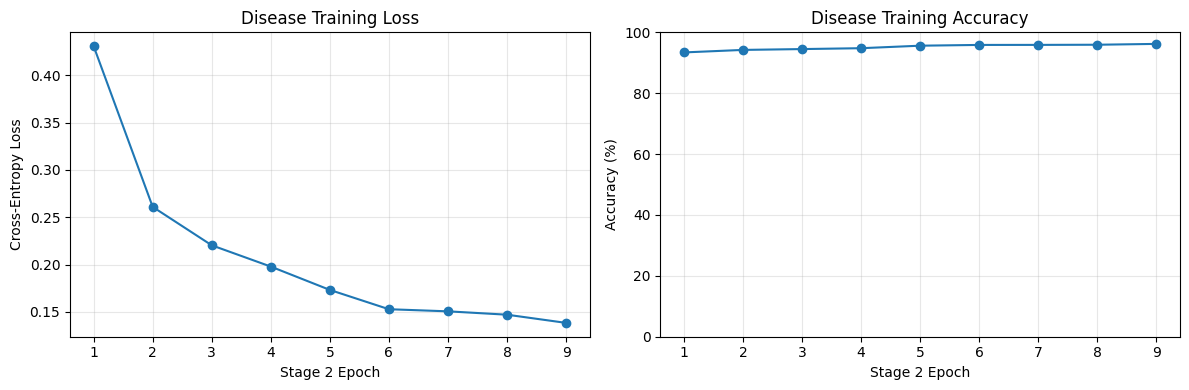

Stage2 disease 10/10:   0%|          | 0/500 [00:00<?, ?it/s]


DISEASE — STAGE 2 EPOCH 10/10
Train Loss: 0.1326
Train Accuracy: 96.43%
Highest Training Accuracy: 96.43% (Epoch 10)
Checkpoint: epoch_10.pt


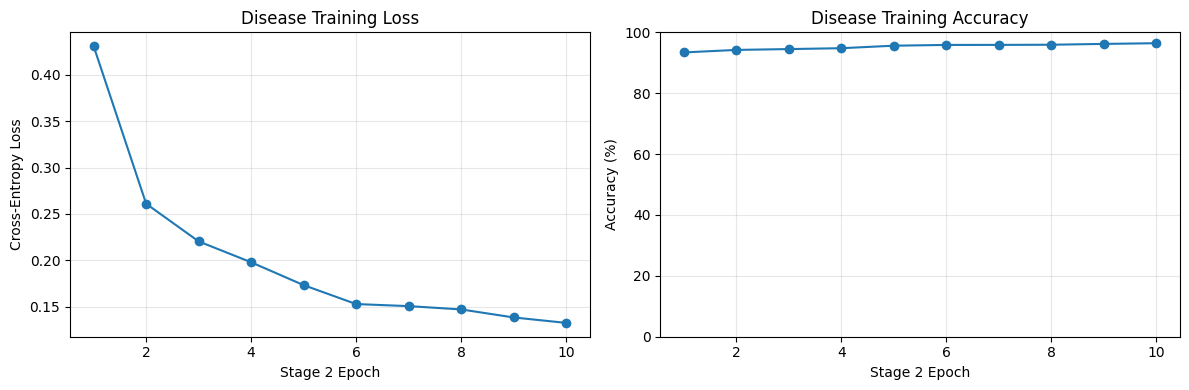


DISEASE STAGE 2 COMPLETED
Results: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage2_full8000/disease


,Task,Stage 1 Source Epoch,Stage 2 Selected Epoch,Training Accuracy (%),Training Loss
0,Crop,29,9,99.28,0.03
1,Disease,16,10,96.43,0.13



Training complete.
All 10 epoch checkpoints saved per task.
Summary: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage2_full8000/stage2_summary.csv
Official Test was NOT performed.


In [ ]:

# ============================================================
# STAGE 2 — CELL 3
# Run Crop and Disease Full-Data Fine-Tuning
# ============================================================

from IPython.display import display

print("=" * 65)
print("CONVNEXT-TINY — STAGE 2 FULL-DATA FINE-TUNING")
print("=" * 65)

# Independent Crop CNN
train_stage2("crop")

# Independent Disease CNN
train_stage2("disease")

# ------------------------------------------------------------
# Final training summary
# ------------------------------------------------------------

summary = []

for task in ("crop", "disease"):

    folder = stage2_dir(task)
    history = pd.read_csv(folder / "history.csv")

    assert len(history) == STAGE2_EPOCHS
    assert history.epoch.tolist() == list(
        range(1, STAGE2_EPOCHS + 1)
    )

    ckpt = torch.load(
        folder / "best_train_acc.pt",
        map_location="cpu",
        weights_only=False
    )

    summary.append({
        "Task": task.title(),
        "Stage 1 Source Epoch": ckpt["source_stage1_epoch"],
        "Stage 2 Selected Epoch": ckpt["epoch"],
        "Training Accuracy (%)": (
            ckpt["train_acc"] * 100
        ),
        "Training Loss": ckpt["train_loss"],
        "Checkpoint": str(
            folder / "best_train_acc.pt"
        )
    })

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    STAGE2_ROOT / "stage2_summary.csv",
    index=False
)

display(
    summary_df[
        [
            "Task",
            "Stage 1 Source Epoch",
            "Stage 2 Selected Epoch",
            "Training Accuracy (%)",
            "Training Loss"
        ]
    ].round(2)
)

print("\nTraining complete.")
print("All 10 epoch checkpoints saved per task.")
print("Summary:", STAGE2_ROOT / "stage2_summary.csv")
print("Official Test was NOT performed.")



### Selected Stage 2 Checkpoints

| Model | Stage 1 Source | Selected Stage 2 Epoch | Training Accuracy |
|---|---:|---:|---:|
| Crop CNN | Epoch 29 | Epoch 9 | 99.28% |
| Disease CNN | Epoch 16 | Epoch 10 | 96.43% |

Both selected models are evaluated on the official test sets in the next section.



# Stage 3 — Official Test Evaluation

Evaluate the selected Stage 2 Crop and Disease CNNs on the held-out DPD-Small official test sets.

- **Official Seen:** 2,000 images
- **Official Unseen:** 1,448 images

Evaluation includes Crop, Disease and Composition Top-1 and Top-5 Accuracy, as well as the seen–unseen harmonic mean.

The official test sets are not used for training or checkpoint selection.


In [ ]:

# ============================================================
# CONVNEXT-TINY — OFFICIAL TEST EVALUATION
# CELL 1: DATA + SELECTED CHECKPOINTS
# NO TRAINING
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from IPython.display import display

EVAL_ROOT = (
    RESULTS_ROOT / "stage3_official_evaluation"
)
EVAL_ROOT.mkdir(parents=True, exist_ok=True)

STAGE2_DIR = RESULTS_ROOT / "stage2_full8000"

SELECTED_PATHS = {
    "crop": STAGE2_DIR / "crop" / "best_train_acc.pt",
    "disease": STAGE2_DIR / "disease" / "best_train_acc.pt",
}

EXPECTED_EPOCHS = {"crop": 9, "disease": 10}

# Read original headerless Official CSVs
COLUMNS = [
    "filename", "crop_id", "disease_id",
    "composition_id", "crop_name",
    "disease_name", "composition_name"
]

def read_official_csv(filename):
    local_path = LOCAL_PROJECT / filename
    drive_path = DRIVE_PROJECT / filename

    path = (
        local_path if local_path.exists()
        else drive_path
    )

    assert path.exists(), f"Missing: {filename}"

    with open(path, encoding="utf-8-sig") as f:
        first = f.readline().split(",")[0].strip().lower()

    df = pd.read_csv(
        path,
        header=0 if first == "filename" else None,
        names=COLUMNS,
        encoding="utf-8-sig"
    )

    for col in (
        "crop_id", "disease_id", "composition_id"
    ):
        df[col] = pd.to_numeric(
            df[col], errors="raise"
        ).astype(int)

    assert df.filename.is_unique
    return df


official_dfs = {
    "seen": read_official_csv(
        "DPD_Small_test_seen.csv"
    ),
    "unseen": read_official_csv(
        "DPD_Small_test_unseen.csv"
    )
}

assert len(official_dfs["seen"]) == 2000
assert len(official_dfs["unseen"]) == 1448

training_files = (
    set(train_df.filename)
    | set(val_seen_df.filename)
    | set(val_unseen_df.filename)
)

seen_files = set(official_dfs["seen"].filename)
unseen_files = set(official_dfs["unseen"].filename)

assert not (training_files & seen_files)
assert not (training_files & unseen_files)
assert not (seen_files & unseen_files)

for split, df in official_dfs.items():
    assert set(df.crop_id).issubset(set(crop_ids))
    assert set(df.disease_id).issubset(
        set(disease_ids)
    )

    missing = set(df.filename) - set(image_lookup)

    assert not missing, (
        f"{split}: Missing image files: "
        f"{sorted(missing)[:5]}. "
        "Rerun the dataset copy/indexing cells."
    )

# Verify saved Stage 2 checkpoints
for task, path in SELECTED_PATHS.items():
    assert path.exists(), f"Missing checkpoint: {path}"

    ckpt = torch.load(
        path, map_location="cpu", weights_only=False
    )

    assert ckpt["task"] == task
    assert ckpt["stage"] == 2
    assert ckpt["backbone"] == "convnext_tiny"
    assert ckpt["pretrained_weights"] == "IMAGENET1K_V1"
    assert ckpt["fine_tuning"] == "full"
    assert list(ckpt["crop_ids"]) == list(crop_ids)
    assert list(ckpt["disease_ids"]) == list(disease_ids)

    assert int(ckpt["epoch"]) == EXPECTED_EPOCHS[task], (
        f"Unexpected {task} epoch: {ckpt['epoch']}"
    )

    print(
        f"{task.upper()}: Stage 2 Epoch {ckpt['epoch']}, "
        f"Training Accuracy {ckpt['train_acc']:.2%}"
    )

    del ckpt

print("\nOFFICIAL DATA VERIFICATION: PASS")
print("Official Seen:", len(official_dfs["seen"]))
print("Official Unseen:", len(official_dfs["unseen"]))
print("AMP:", AMP)
print("Candidate Pairs:", len(crop_ids) * len(disease_ids))
print("Output:", EVAL_ROOT)


CROP: Stage 2 Epoch 9, Training Accuracy 99.28%
DISEASE: Stage 2 Epoch 10, Training Accuracy 96.43%

OFFICIAL DATA VERIFICATION: PASS
Official Seen: 2000
Official Unseen: 1448
AMP: True
Candidate Pairs: 9625
Output: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage3_official_evaluation



## 17. Final Model Evaluation

Load the selected Stage 2 checkpoints and generate predictions for both official test sets.

Composition predictions are calculated from the combined Crop and Disease log probabilities. Evaluation results and image-level predictions are saved to Google Drive.


In [ ]:

# ============================================================
# CELL 2 — OFFICIAL EVALUATION
# Crop + Disease + Composition Top-1 / Top-5
# Percentage display + Save results
# NO TRAINING / NO CHECKPOINT SELECTION
# ============================================================

import gc
from tqdm.auto import tqdm

def load_final_model(task):
    path = SELECTED_PATHS[task]

    ckpt = torch.load(
        path, map_location="cpu", weights_only=False
    )

    model = build_model(
        task,
        ckpt["config"]["dropout"],
        pretrained=False
    )

    model.load_state_dict(
        ckpt["state_dict"],
        strict=True
    )

    model.eval()

    return model


@torch.inference_mode()
def collect_probabilities(model, loader, task, split):
    outputs = []

    for images, _, _ in tqdm(
        loader,
        desc=f"{task.upper()} Official {split}",
        leave=True
    ):
        images = images.to(
            DEVICE, non_blocking=True
        )

        with torch.autocast("cuda", enabled=AMP):
            logits = model(images)

        log_probs = F.log_softmax(
            logits.float(), dim=1
        )

        outputs.append(log_probs.cpu().numpy())

    return np.concatenate(outputs, axis=0)


def official_hm(a, b):
    return 2 * a * b / (a + b) if a + b else 0.0


all_metrics = {}
all_rows = []

crop_model = load_final_model("crop")
disease_model = load_final_model("disease")

try:
    for split in ("seen", "unseen"):

        df = official_dfs[split].reset_index(drop=True)

        loader = make_loader(
            df,
            training=False,
            batch_size=16
        )

        crop_log = collect_probabilities(
            crop_model, loader, "crop", split
        )

        disease_log = collect_probabilities(
            disease_model, loader, "disease", split
        )

        n = len(df)

        assert crop_log.shape == (n, 55)
        assert disease_log.shape == (n, 175)

        true_crop = np.array([
            crop_index[int(v)] for v in df.crop_id
        ])

        true_disease = np.array([
            disease_index[int(v)] for v in df.disease_id
        ])

        # Independent classification rankings
        crop_rank = np.argsort(
            -crop_log, axis=1
        )[:, :5]

        disease_rank = np.argsort(
            -disease_log, axis=1
        )[:, :5]

        # Factorised scores over all 9,625 pairs
        scores = (
            crop_log[:, :, None]
            + disease_log[:, None, :]
        ).reshape(n, 9625)

        comp_rank = np.argsort(
            -scores, axis=1
        )[:, :5]

        true_pair = true_crop * 175 + true_disease

        crop_correct1 = crop_rank[:, 0] == true_crop
        crop_correct5 = (
            crop_rank == true_crop[:, None]
        ).any(axis=1)

        disease_correct1 = (
            disease_rank[:, 0] == true_disease
        )
        disease_correct5 = (
            disease_rank == true_disease[:, None]
        ).any(axis=1)

        comp_correct1 = comp_rank[:, 0] == true_pair
        comp_correct5 = (
            comp_rank == true_pair[:, None]
        ).any(axis=1)

        metrics = {
            "crop_top1": float(crop_correct1.mean()),
            "crop_top5": float(crop_correct5.mean()),
            "disease_top1": float(disease_correct1.mean()),
            "disease_top5": float(disease_correct5.mean()),
            "composition_top1": float(comp_correct1.mean()),
            "composition_top5": float(comp_correct5.mean())
        }

        all_metrics[split] = metrics

        predicted_crop = np.array(crop_ids)[
            crop_rank[:, 0]
        ]

        predicted_disease = np.array(disease_ids)[
            disease_rank[:, 0]
        ]

        predictions = df.copy()

        predictions["pred_crop_id"] = predicted_crop
        predictions["pred_disease_id"] = predicted_disease

        predictions["crop_top1_correct"] = crop_correct1
        predictions["crop_top5_correct"] = crop_correct5

        predictions["disease_top1_correct"] = disease_correct1
        predictions["disease_top5_correct"] = disease_correct5

        predictions["composition_top1_correct"] = comp_correct1
        predictions["composition_top5_correct"] = comp_correct5

        predictions["pred_top5_pairs"] = [
            json.dumps([
                [
                    int(crop_ids[p // 175]),
                    int(disease_ids[p % 175])
                ]
                for p in row
            ])
            for row in comp_rank
        ]

        predictions.to_csv(
            EVAL_ROOT /
            f"official_{split}_predictions.csv",
            index=False
        )

        print(f"\nOFFICIAL {split.upper()} — TOP-1")
        print(
            f"Crop: {metrics['crop_top1']:.2%} | "
            f"Disease: {metrics['disease_top1']:.2%} | "
            f"Composition: {metrics['composition_top1']:.2%}"
        )

        print(f"OFFICIAL {split.upper()} — TOP-5")
        print(
            f"Crop: {metrics['crop_top5']:.2%} | "
            f"Disease: {metrics['disease_top5']:.2%} | "
            f"Composition: {metrics['composition_top5']:.2%}"
        )

        del loader, crop_log, disease_log, scores
        gc.collect()

finally:
    del crop_model, disease_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Final comparison — DISPLAY ALL AS PERCENTAGES
# ------------------------------------------------------------

for task in ("crop", "disease", "composition"):
    for k in (1, 5):

        key = f"{task}_top{k}"

        seen = all_metrics["seen"][key]
        unseen = all_metrics["unseen"][key]

        all_rows.append({
            "Task": task.title(),
            "Top-K": k,
            "Seen (%)": seen * 100,
            "Unseen (%)": unseen * 100,
            "HM (%)": official_hm(seen, unseen) * 100
        })

results_df = pd.DataFrame(all_rows)

print("\n" + "=" * 65)
print("CONVNEXT-TINY — OFFICIAL TEST RESULTS")
print("=" * 65)

display(results_df.round(2))

# Save metrics
results_df.to_csv(
    EVAL_ROOT / "official_results_percent.csv",
    index=False
)

with open(
    EVAL_ROOT / "official_raw_metrics.json", "w"
) as f:
    json.dump(
        {
            "backbone": "convnext_tiny",
            "weights": "IMAGENET1K_V1",
            "stage": 2,
            "crop_epoch": EXPECTED_EPOCHS["crop"],
            "disease_epoch": EXPECTED_EPOCHS["disease"],
            "selection": "highest_training_accuracy",
            "candidate_pairs": 9625,
            "amp": AMP,
            "seen": all_metrics["seen"],
            "unseen": all_metrics["unseen"]
        },
        f,
        indent=2
    )

print("\nSaved to:", EVAL_ROOT)
print("No model training or checkpoint selection performed.")


CROP Official seen:   0%|          | 0/125 [00:00<?, ?it/s]

DISEASE Official seen:   0%|          | 0/125 [00:00<?, ?it/s]


OFFICIAL SEEN — TOP-1
Crop: 89.30% | Disease: 66.25% | Composition: 63.65%
OFFICIAL SEEN — TOP-5
Crop: 96.20% | Disease: 88.45% | Composition: 84.00%


CROP Official unseen:   0%|          | 0/91 [00:00<?, ?it/s]

DISEASE Official unseen:   0%|          | 0/91 [00:00<?, ?it/s]


OFFICIAL UNSEEN — TOP-1
Crop: 73.07% | Disease: 11.12% | Composition: 6.56%
OFFICIAL UNSEEN — TOP-5
Crop: 84.74% | Disease: 26.73% | Composition: 18.85%

CONVNEXT-TINY — OFFICIAL TEST RESULTS


,Task,Top-K,Seen (%),Unseen (%),HM (%)
0,Crop,1,89.30,73.07,80.37
1,Crop,5,96.20,84.74,90.11
2,Disease,1,66.25,11.12,19.04
3,Disease,5,88.45,26.73,41.05
4,Composition,1,63.65,6.56,11.90
5,Composition,5,84.00,18.85,30.80



Saved to: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage3_official_evaluation
No model training or checkpoint selection performed.



## 18. Final Official Test Results

| Task | Seen Top-1 | Unseen Top-1 | HM |
|---|---:|---:|---:|
| Crop | 89.30% | 73.07% | 80.37% |
| Disease | 66.25% | 11.12% | 19.04% |
| Composition | 63.65% | 6.56% | **11.90%** |

The final ConvNeXt-Tiny model achieved a Composition HM of **11.90%** on the official test sets.

Crop classification performed considerably better than disease classification, particularly on unseen compositions. This indicates that unseen disease recognition remains the main limitation of the baseline.
